# Express Links · Week 1, step 3: Graph WaveNet baseline

This notebook trains **Graph WaveNet on the original METR-LA road graph, with its learned links switched off**. This is the "original road graph" baseline of proposal 3.3: every later run uses this same code, and only the graph file changes.

**What it does**

1. Loads the train / val / test files from step 2 (`Coding/data/processed/<dataset>/`) and the road graph.
2. Builds Graph WaveNet exactly as the official repo does (pinned commit), with **no `addaptadj`**: the model can only pass information along the graph we give it.
3. Trains for 100 epochs with a **fixed seed**, keeps the epoch with the lowest validation MAE (as Graph WaveNet does), and **saves a checkpoint every epoch to Drive**. If Colab disconnects, just run all again: it resumes from the last finished epoch.
4. Tests the best epoch and reports **MAE, RMSE and MAPE at 15, 30 and 60 min** plus the 12-step average.
5. Saves the **test forecasts** (in mph, with each sample's time), which step 9 (jam scoring) will use.
6. Checks the result against the published number for this exact setting.

**What "close to published" means here.** The headline Graph WaveNet numbers (2.69 / 3.07 / 3.53 MAE at 15 / 30 / 60 min) include the learned links. Our setting is the paper's **"Forward-backward"** row of the adjacency ablation (Table 3): **MAE 3.08, RMSE 6.13, MAPE 8.25 %, averaged over the 12 horizons** (full model: 3.04). That 12-step average is what we compare against. Expect the 60-min MAE to be a little above 3.53.

**Run it:** Runtime → Change runtime type → **GPU** (T4 is enough), then Runtime → Run all. Expect roughly 1 to 2 minutes per epoch on a T4, so about 2 to 3 hours for 100 epochs. You can close the tab only if you have Colab Pro background execution; otherwise keep it open, and if it disconnects, reconnect and Run all.

**Output folder:** `Coding/runs/<dataset>/<graph>/seed<k>/`, with `log.csv`, `best.pt`, `last.pt`, `results.json`, `test_predictions.npz`, `curves.png`. One row per run is also added to `Coding/runs/results.csv`.

## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob

# Find the shared 'Coding' folder. It works whether the folder is in your own Drive or is
# your teammate's folder added to My Drive as a shortcut (Organize -> Add shortcut -> My Drive).
FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
hits = []
for root in ROOTS:
    for depth in range(4):                      # the folder may sit up to 3 levels down
        hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
              "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
PROJECT_DIR = hits[0]
print('PROJECT_DIR =', PROJECT_DIR)

# Results are written into the shared folder, so you need Editor access to it
try:
    probe = os.path.join(PROJECT_DIR, '.write_test')
    open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings

For the baseline, leave everything as it is. The later runs only change `GRAPH_NAME` / `GRAPH_FILE` (week 3: the 7 graph versions) and `SEED` (0, 1, 2), and `DATASET` for PEMS-BAY.

Model and training settings are Graph WaveNet's defaults (the ones behind the published numbers). Do not change them between runs, or the comparison stops being fair.

In [ ]:
DATASET    = 'METR-LA'      # 'METR-LA' or 'PEMS-BAY'
GRAPH_NAME = 'original'     # name used for the output folder and results table
GRAPH_FILE = None           # None = the original road graph of DATASET; otherwise a .pkl in the same format
SEED       = 0              # the plan uses seeds 0, 1, 2

# Graph WaveNet defaults (train.py of the official repo). Keep fixed across all runs.
EPOCHS       = 100
BATCH_SIZE   = 64
LR           = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.3
NHID         = 32
ADJ_TYPE     = 'doubletransition'   # forward + backward random-walk matrices
ADAPTIVE_ADJ = False                # learned links OFF: the graph we give is the only graph

# ---------------------------------------------------------------------------------
ORIGINAL_GRAPHS = {'METR-LA': 'adj_mx.pkl', 'PEMS-BAY': 'adj_mx_bay.pkl'}
DATA_DIR   = os.path.join(PROJECT_DIR, 'data', 'processed', DATASET)
ORIG_GRAPH = os.path.join(PROJECT_DIR, 'data', 'raw', ORIGINAL_GRAPHS[DATASET])
GRAPH_FILE = GRAPH_FILE or ORIG_GRAPH
RUN_DIR    = os.path.join(PROJECT_DIR, 'runs', DATASET, GRAPH_NAME, f'seed{SEED}')
FIG_DIR    = os.path.join(PROJECT_DIR, 'figures')
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

for p in [os.path.join(DATA_DIR, f'{s}.npz') for s in ['train', 'val', 'test']] + [GRAPH_FILE]:
    assert os.path.exists(p), f'Missing {p}. Run the step 2 notebook first.'
print('data :', DATA_DIR)
print('graph:', GRAPH_FILE)
print('run  :', RUN_DIR)

data : /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/METR-LA
graph: /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/raw/adj_mx.pkl
run  : /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/runs/METR-LA/original/seed0


## 3. Get the Graph WaveNet code

We clone the official repo at a **fixed commit** and use its model, data loader and loss functions unchanged. We do not use its `train.py`: this notebook replaces it so that it can (a) fix the seed (it is commented out in the original), (b) use `cuda:0` (the original defaults to `cuda:3`), (c) resume after a disconnect, and (d) save the forecasts. The training step itself (`engine.train`: masked MAE loss, Adam, gradient clipping at 5) is the original code.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || echo "No GPU found: Runtime -> Change runtime type -> GPU"

import sys, subprocess
GWN_DIR    = '/content/Graph-WaveNet'
GWN_COMMIT = '6b162e80c59a1d494809252eca055cff93dc66b1'
if not os.path.isdir(GWN_DIR):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/nnzhan/Graph-WaveNet.git', GWN_DIR], check=True)
subprocess.run(['git', '-C', GWN_DIR, 'checkout', '-q', GWN_COMMIT], check=True)

# Compatibility fix for current PyTorch. The 2019 code builds some layers with nn.Conv1d but feeds them
# 4-D tensors with (1, k) kernels; old PyTorch silently treated them as Conv2d, new PyTorch refuses.
# Conv2d with the same arguments is exactly what the old version computed, so the model is unchanged.
model_py = os.path.join(GWN_DIR, 'model.py')
src = open(model_py).read()
if 'nn.Conv1d(' in src:
    open(model_py, 'w').write(src.replace('nn.Conv1d(', 'nn.Conv2d('))
    print('Patched model.py: Conv1d -> Conv2d (same layers, works with current PyTorch)')
    if 'model' in sys.modules or 'engine' in sys.modules:
        raise RuntimeError('The unpatched model is already loaded. Runtime -> Restart session, then Run all.')
if GWN_DIR not in sys.path:
    sys.path.insert(0, GWN_DIR)

import json, time, random
import numpy as np
import pandas as pd
import torch
import util                      # Graph WaveNet: data loader, graph loader, masked metrics
from engine import trainer       # Graph WaveNet: model + one training / evaluation step

print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())

Tesla T4, 15360 MiB
torch 2.11.0+cu130 | CUDA available: True


## 4. Load the data and the graph

`util.load_dataset` standardises the input speeds with the training mean and std (zeros included, as in Graph WaveNet); targets stay in mph. The checks below should all print `OK`.

In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    print('WARNING: no GPU. This will be far too slow for 100 epochs.')

data   = util.load_dataset(DATA_DIR, BATCH_SIZE, BATCH_SIZE, BATCH_SIZE)
scaler = data['scaler']
t_anchor_test = np.load(os.path.join(DATA_DIR, 'test.npz'))['t_anchor']
N = data['x_train'].shape[2]

sensor_ids, _, adj = util.load_adj(GRAPH_FILE, ADJ_TYPE)
orig_ids = util.load_pickle(ORIG_GRAPH)[0]
assert len(sensor_ids) == N, f'graph has {len(sensor_ids)} sensors, data has {N}'
assert [str(s) for s in sensor_ids] == [str(s) for s in orig_ids], 'sensor order differs from the original graph'
print(f'OK  graph and data both have {N} sensors, in the same order')

for k, v in {'train': data['x_train'], 'val': data['x_val'], 'test': data['x_test']}.items():
    print(f'OK  {k:5s} x {v.shape}  y {data["y_" + k].shape}')
print(f'OK  input scaling: mean {scaler.mean:.2f} mph, std {scaler.std:.2f} mph (training inputs, zeros included)')

supports = [torch.tensor(np.asarray(a), dtype=torch.float32).to(device) for a in adj]
n_links = int((np.asarray(util.load_pickle(GRAPH_FILE)[2]) > 0).sum())
print(f'OK  {len(supports)} graph matrices ({ADJ_TYPE}); {n_links:,} non-zero entries in the graph file')

OK  graph and data both have 207 sensors, in the same order
OK  train x (23974, 12, 207, 2)  y (23974, 12, 207, 2)
OK  val   x (3425, 12, 207, 2)  y (3425, 12, 207, 2)
OK  test  x (6850, 12, 207, 2)  y (6850, 12, 207, 2)
OK  input scaling: mean 54.41 mph, std 19.49 mph (training inputs, zeros included)
OK  2 graph matrices (doubletransition); 1,722 non-zero entries in the graph file


## 5. Build the model (learned links off)

`gcn_bool=True` (graph convolution on), `addaptadj=False` (no learned links), `aptinit=None`. The check confirms the model has no learned node vectors.

In [ ]:
engine = trainer(scaler, in_dim=2, seq_length=12, num_nodes=N, nhid=NHID, dropout=DROPOUT,
                 lrate=LR, wdecay=WEIGHT_DECAY, device=device, supports=supports,
                 gcn_bool=True, addaptadj=ADAPTIVE_ADJ, aptinit=None)

names = [n for n, _ in engine.model.named_parameters()]
assert not any('nodevec' in n for n in names), 'learned links are ON; they must be off'
n_params = sum(p.numel() for p in engine.model.parameters())
print(f'OK  learned links off (no node vectors); {n_params:,} parameters')

CONFIG = dict(dataset=DATASET, graph=GRAPH_NAME, graph_file=os.path.basename(GRAPH_FILE), seed=SEED,
              epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, weight_decay=WEIGHT_DECAY, dropout=DROPOUT,
              nhid=NHID, adj_type=ADJ_TYPE, adaptive_adj=ADAPTIVE_ADJ, gwn_commit=GWN_COMMIT)

# ---- Resume if this run already has finished epochs ----
LAST, BEST = os.path.join(RUN_DIR, 'last.pt'), os.path.join(RUN_DIR, 'best.pt')
start_epoch, history, train_seconds = 1, [], 0.0
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location='cpu', weights_only=False)
    assert ck['config'] == CONFIG, ('This run folder was made with different settings:\n'
                                    f'{ck["config"]}\nDelete it or change GRAPH_NAME / SEED.')
    engine.model.load_state_dict(ck['model'])
    engine.optimizer.load_state_dict(ck['optimizer'])
    history, train_seconds = ck['history'], ck['train_seconds']
    start_epoch = ck['epoch'] + 1
    torch.set_rng_state(ck['torch_rng'])
    if ck['cuda_rng'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ck['cuda_rng'])
    print(f'Resuming after epoch {ck["epoch"]} (best val MAE so far {min(h["val_mae"] for h in history):.4f})')
else:
    print('Starting a new run')

OK  learned links off (no node vectors); 288,876 parameters
Resuming after epoch 44 (best val MAE so far 2.8071)


## 6. Train

Same loop as Graph WaveNet's `train.py`: each epoch shuffles the training samples, trains on every batch, then measures the validation error. The shuffle order of epoch *e* depends only on (seed, *e*), so a resumed run sees the same order as an uninterrupted one.

After every epoch: `last.pt` (for resuming) is overwritten, `best.pt` is updated if validation MAE improved, and `log.csv` gets a row. All errors are in mph and ignore missing (zero) readings.

In [ ]:
def save_atomic(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

train_loader = data['train_loader']              # padded to a multiple of the batch size, as in Graph WaveNet
X, Y, n_batches = train_loader.xs, train_loader.ys, train_loader.num_batch

for epoch in range(start_epoch, EPOCHS + 1):
    # ---- train ----
    perm = np.random.default_rng(SEED * 10_000 + epoch).permutation(train_loader.size)
    t0 = time.time()
    tr = []
    for b in range(n_batches):
        idx = perm[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
        x = torch.from_numpy(X[idx]).float().to(device).transpose(1, 3)
        y = torch.from_numpy(Y[idx]).float().to(device).transpose(1, 3)
        tr.append(engine.train(x, y[:, 0, :, :]))           # (MAE, MAPE, RMSE) on this batch
    t_train = time.time() - t0

    # ---- validate ----
    va = []
    with torch.no_grad():
        for x, y in data['val_loader'].get_iterator():
            x = torch.from_numpy(x).float().to(device).transpose(1, 3)
            y = torch.from_numpy(y).float().to(device).transpose(1, 3)
            va.append(engine.eval(x, y[:, 0, :, :]))
    tr, va = np.mean(tr, axis=0), np.mean(va, axis=0)
    train_seconds += t_train

    row = dict(epoch=epoch, train_mae=tr[0], train_mape=tr[1] * 100, train_rmse=tr[2],
               val_mae=va[0], val_mape=va[1] * 100, val_rmse=va[2], train_sec=t_train)
    is_best = not history or row['val_mae'] < min(h['val_mae'] for h in history)
    history.append(row)

    if is_best:
        save_atomic({'model': engine.model.state_dict(), 'epoch': epoch, 'val_mae': row['val_mae'],
                     'config': CONFIG}, BEST)
    save_atomic({'model': engine.model.state_dict(), 'optimizer': engine.optimizer.state_dict(),
                 'epoch': epoch, 'history': history, 'train_seconds': train_seconds, 'config': CONFIG,
                 'torch_rng': torch.get_rng_state(),
                 'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}, LAST)
    pd.DataFrame(history).to_csv(os.path.join(RUN_DIR, 'log.csv'), index=False)

    print(f'epoch {epoch:3d}/{EPOCHS} | train MAE {row["train_mae"]:.3f} | val MAE {row["val_mae"]:.3f} '
          f'RMSE {row["val_rmse"]:.3f} MAPE {row["val_mape"]:.2f}% | {t_train:.0f} s'
          + ('  <- best' if is_best else ''), flush=True)

print(f'Training done: {len(history)} epochs, {train_seconds / 3600:.2f} GPU-hours of training')

epoch  45/100 | train MAE 2.928 | val MAE 2.800 RMSE 5.358 MAPE 7.80% | 136 s  <- best
epoch  46/100 | train MAE 2.927 | val MAE 2.811 RMSE 5.412 MAPE 7.92% | 134 s
epoch  47/100 | train MAE 2.932 | val MAE 2.850 RMSE 5.422 MAPE 8.16% | 134 s
epoch  48/100 | train MAE 2.926 | val MAE 2.840 RMSE 5.449 MAPE 8.12% | 133 s
epoch  49/100 | train MAE 2.926 | val MAE 2.807 RMSE 5.401 MAPE 7.68% | 133 s
epoch  50/100 | train MAE 2.911 | val MAE 2.814 RMSE 5.429 MAPE 7.74% | 133 s
epoch  51/100 | train MAE 2.916 | val MAE 2.850 RMSE 5.502 MAPE 8.17% | 133 s
epoch  52/100 | train MAE 2.910 | val MAE 2.808 RMSE 5.413 MAPE 7.92% | 133 s
epoch  53/100 | train MAE 2.911 | val MAE 2.839 RMSE 5.511 MAPE 7.79% | 133 s
epoch  54/100 | train MAE 2.907 | val MAE 2.820 RMSE 5.441 MAPE 8.01% | 133 s
epoch  55/100 | train MAE 2.907 | val MAE 2.873 RMSE 5.468 MAPE 7.78% | 133 s
epoch  56/100 | train MAE 2.904 | val MAE 2.807 RMSE 5.418 MAPE 7.81% | 134 s
epoch  57/100 | train MAE 2.904 | val MAE 2.822 RMSE 5.

## 7. Test the best epoch

Loads the epoch with the lowest validation MAE (as Graph WaveNet does) and forecasts every test sample. Horizon *h* means *h* × 5 minutes ahead: 3 = 15 min, 6 = 30 min, 12 = 60 min.

The forecasts are saved as `test_predictions.npz`:

| Array | Shape | Meaning |
|---|---|---|
| `pred` | (samples, 12, sensors) | forecast speed in mph, same layout as `y[..., 0]` in `test.npz` |
| `t_anchor` | (samples,) | "now" of each sample (its last input reading) |
| `horizon_min` | (12,) | minutes ahead: 5, 10, …, 60 |

The true speeds are `y[..., 0]` in the step 2 `test.npz`, in the same order.

In [ ]:
best = torch.load(BEST, map_location='cpu', weights_only=False)
engine.model.load_state_dict(best['model'])
engine.model.eval()

outs = []
with torch.no_grad():
    for x, _ in data['test_loader'].get_iterator():
        x = torch.from_numpy(x).float().to(device).transpose(1, 3)
        outs.append(engine.model(x).transpose(1, 3)[:, 0, :, :])      # (batch, sensors, 12), scaled
S = data['y_test'].shape[0]
yhat = scaler.inverse_transform(torch.cat(outs, dim=0)[:S])            # mph
real = torch.from_numpy(data['y_test'][..., 0]).float().to(device).transpose(1, 2)   # (S, sensors, 12)

per_h = []
for h in range(12):
    mae, mape, rmse = util.metric(yhat[:, :, h], real[:, :, h])
    per_h.append(dict(horizon=h + 1, minutes=5 * (h + 1), mae=mae, rmse=rmse, mape=mape * 100))
per_h = pd.DataFrame(per_h)
avg = per_h[['mae', 'rmse', 'mape']].mean()

pred_np = yhat.transpose(1, 2).cpu().numpy().astype(np.float32)          # (S, 12, sensors)
np.savez_compressed(os.path.join(RUN_DIR, 'test_predictions.npz'), pred=pred_np,
                    t_anchor=t_anchor_test, horizon_min=np.arange(5, 61, 5))
per_h.to_csv(os.path.join(RUN_DIR, 'test_by_horizon.csv'), index=False)

pick = per_h.set_index('minutes').loc[[15, 30, 60], ['mae', 'rmse', 'mape']]
pick.loc['avg (12 steps)'] = avg
print(f'Best epoch {best["epoch"]} (val MAE {best["val_mae"]:.4f}). Test errors (mph; MAPE in %):')
print(pick.round(3).to_string())

Best epoch 82 (val MAE 2.7689). Test errors (mph; MAPE in %):
                  mae   rmse    mape
minutes                             
15              2.707  5.186   6.983
30              3.096  6.250   8.475
60              3.579  7.410  10.180
avg (12 steps)  3.065  6.117   8.336


## 8. Save the results row and check against the published number

The check compares our **12-step average** with the paper's row for this exact setting (forward-backward graph, no learned links). Seed-to-seed noise for Graph WaveNet is a few hundredths of a mph, so:

* within **+0.05 mph**: matches; the setup is trusted;
* **+0.05 to +0.10**: close; acceptable, mention it in the report;
* more than **+0.10**: something differs from the published setup. Fix it before any comparison run (plan: risk "Graph WaveNet misses its usual score").

In [ ]:
import platform
REF_AVG  = {'METR-LA': dict(mae=3.08, rmse=6.13, mape=8.25), 'PEMS-BAY': dict(mae=1.59, rmse=3.55, mape=3.57)}
REF_FULL = {'METR-LA': {15: 2.69, 30: 3.07, 60: 3.53}, 'PEMS-BAY': {15: 1.30, 30: 1.63, 60: 1.95}}  # with learned links

ref = REF_AVG[DATASET]
gap = avg['mae'] - ref['mae']
if gap <= 0.05:   verdict = 'MATCHES the published number: the baseline is trusted.'
elif gap <= 0.10: verdict = 'CLOSE to the published number: acceptable, note the gap in the report.'
else:             verdict = 'OFF from the published number: fix the setup before any comparison run.'

results = dict(CONFIG,
    best_epoch=int(best['epoch']), best_val_mae=float(best['val_mae']),
    **{f'{m}_{k}min': float(per_h.set_index('minutes').loc[k, m]) for k in [15, 30, 60] for m in ['mae', 'rmse', 'mape']},
    mae_avg=float(avg['mae']), rmse_avg=float(avg['rmse']), mape_avg=float(avg['mape']),
    published_avg_mae=ref['mae'], gap_mae=float(gap), verdict=verdict.split(':')[0],
    params=int(n_params), train_hours=round(train_seconds / 3600, 3),
    sec_per_epoch=round(float(np.mean([h['train_sec'] for h in history])), 1),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    torch=torch.__version__, python=platform.python_version(),
    finished=time.strftime('%Y-%m-%d %H:%M'))
with open(os.path.join(RUN_DIR, 'results.json'), 'w') as f:
    json.dump(results, f, indent=2)

# One row per (dataset, graph, seed) in the shared results table; a rerun replaces its old row
table_path = os.path.join(PROJECT_DIR, 'runs', 'results.csv')
table = pd.read_csv(table_path) if os.path.exists(table_path) else pd.DataFrame()
if len(table):
    table = table[~((table['dataset'] == DATASET) & (table['graph'] == GRAPH_NAME) & (table['seed'] == SEED))]
table = pd.concat([table, pd.DataFrame([results])], ignore_index=True)
table.to_csv(table_path, index=False)

print(f'Our 12-step average  : MAE {avg["mae"]:.3f}  RMSE {avg["rmse"]:.3f}  MAPE {avg["mape"]:.2f}%')
print(f'Published (same setup): MAE {ref["mae"]:.2f}  RMSE {ref["rmse"]:.2f}  MAPE {ref["mape"]:.2f}%')
print(f'Gap in MAE: {gap:+.3f} mph  ->  {verdict}')
print(f'\nFor context, the full model WITH learned links: '
      + ', '.join(f'{k} min {v}' for k, v in REF_FULL[DATASET].items()) + ' mph MAE.')
print(f'\nSaved {RUN_DIR}/results.json and a row in {table_path}')

Our 12-step average  : MAE 3.065  RMSE 6.117  MAPE 8.34%
Published (same setup): MAE 3.08  RMSE 6.13  MAPE 8.25%
Gap in MAE: -0.015 mph  ->  MATCHES the published number: the baseline is trusted.

For context, the full model WITH learned links: 15 min 2.69, 30 min 3.07, 60 min 3.53 mph MAE.

Saved /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/runs/METR-LA/original/seed0/results.json and a row in /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/runs/results.csv


## 9. Figures: learning curves and error by horizon

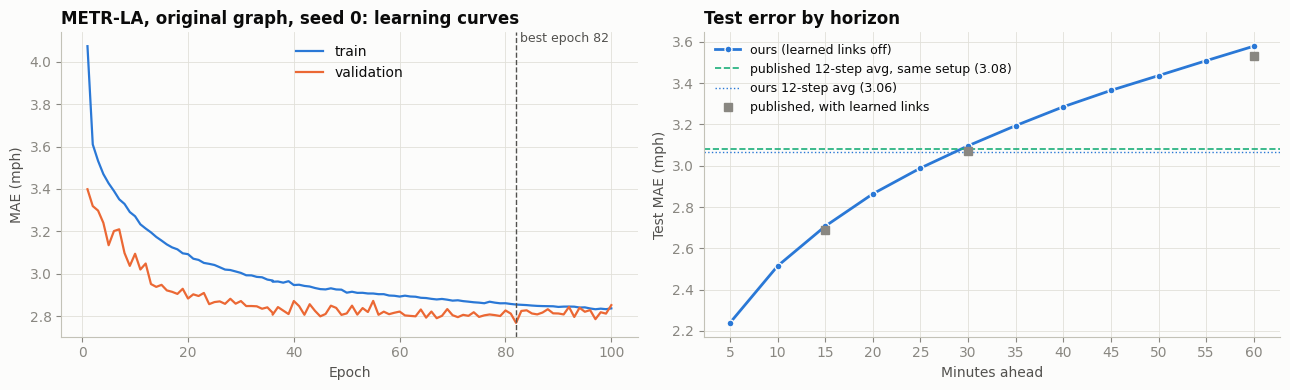

In [ ]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e', 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

h = pd.DataFrame(history)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(h['epoch'], h['train_mae'], color='#2a78d6', lw=1.6, label='train')
a1.plot(h['epoch'], h['val_mae'], color='#eb6834', lw=1.6, label='validation')
a1.axvline(best['epoch'], color='#52514e', lw=1, ls='--')
a1.text(best['epoch'], a1.get_ylim()[1], f' best epoch {best["epoch"]}', va='top', fontsize=9, color='#52514e')
a1.set_xlabel('Epoch'); a1.set_ylabel('MAE (mph)'); a1.legend(frameon=False)
a1.set_title(f'{DATASET}, {GRAPH_NAME} graph, seed {SEED}: learning curves', loc='left')

a2.plot(per_h['minutes'], per_h['mae'], '-o', color='#2a78d6', lw=2, ms=5, mec='#fcfcfb', label='ours (learned links off)')
a2.axhline(ref['mae'], color='#1baf7a', lw=1.2, ls='--', label=f'published 12-step avg, same setup ({ref["mae"]})')
a2.axhline(avg['mae'], color='#2a78d6', lw=1, ls=':', label=f'ours 12-step avg ({avg["mae"]:.2f})')
ks = list(REF_FULL[DATASET])
a2.plot(ks, [REF_FULL[DATASET][k] for k in ks], 's', color=MUTED, ms=6, label='published, with learned links')
a2.set_xticks(range(5, 61, 5)); a2.set_xlabel('Minutes ahead'); a2.set_ylabel('Test MAE (mph)')
a2.legend(frameon=False, fontsize=9); a2.set_title('Test error by horizon', loc='left')

fig.tight_layout()
fig.savefig(os.path.join(RUN_DIR, 'curves.png'), dpi=200, bbox_inches='tight')
fig.savefig(os.path.join(FIG_DIR, f'baseline_{DATASET}_{GRAPH_NAME}_seed{SEED}.png'), dpi=200, bbox_inches='tight')
plt.show()

## Done

Send the team the printout of sections 7 and 8 (the 15 / 30 / 60-min table and the verdict).

* **Verdict MATCHES or CLOSE:** step 3 is done. The same notebook will run every later version: set `GRAPH_NAME`, `GRAPH_FILE` and `SEED`, then Run all.
* **Verdict OFF:** do not start comparison runs. Check first that the runtime had a GPU, all 100 epochs finished, and no setting in section 2 was changed.

Step 9 (jam scoring) reads `test_predictions.npz` from this folder together with `y` and `t_anchor` from the step 2 `test.npz`.